In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Netflix EDA project started!")


Netflix EDA project started!


In [2]:
df = pd.read_csv("../data/netflix_titles.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and columns: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [5]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 8807
Number of columns: 12


In [7]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [8]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [9]:
df.isnull().sum().sort_values(ascending=False)

director        2634
country          831
cast             825
date_added        10
rating             4
duration           3
show_id            0
type               0
title              0
release_year       0
listed_in          0
description        0
dtype: int64

In [10]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [11]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary

,Missing Count,Missing Percentage
director,2634,29.908028
country,831,9.435676
cast,825,9.367549
date_added,10,0.113546
rating,4,0.045418
duration,3,0.034064
show_id,0,0.000000
type,0,0.000000
title,0,0.000000
release_year,0,0.000000


In [12]:
text_columns = [
    "director",
    "cast",
    "country",
    "rating"
]

for column in text_columns:
    df[column] = df[column].fillna("Unknown")

print("Missing values handled in selected columns.")

Missing values handled in selected columns.


In [13]:
df["date_added"] = pd.to_datetime(
    df["date_added"].str.strip(),
    errors="coerce"
)

print("Date conversion completed.")
print(df["date_added"].dtype)

Date conversion completed.
datetime64[us]


In [14]:
print("Dataset shape:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum())

Dataset shape: (8807, 12)

Remaining missing values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64


In [15]:
# Count movies and TV shows
content_count = df["type"].value_counts()

print(content_count)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [16]:
content_percentage = (
    df["type"].value_counts(normalize=True) * 100
)

print(content_percentage.round(2))

type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


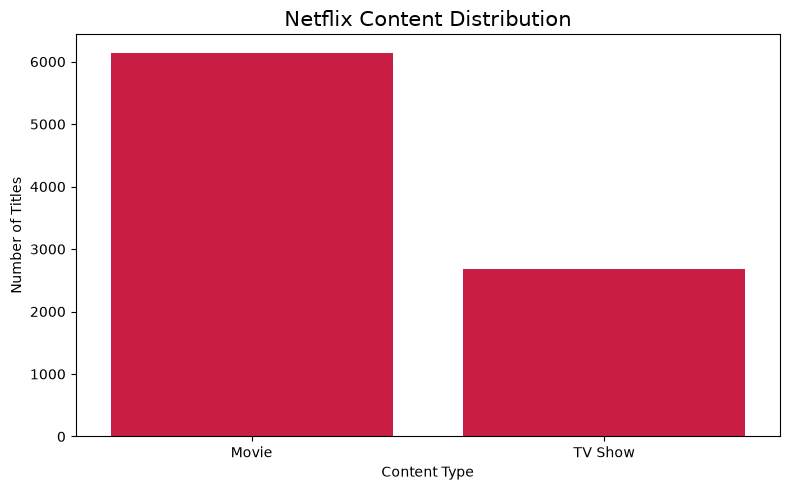

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="type",
    order=["Movie", "TV Show"],
    color="#E50235"
)

plt.title("Netflix Content Distribution", fontsize=15)
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

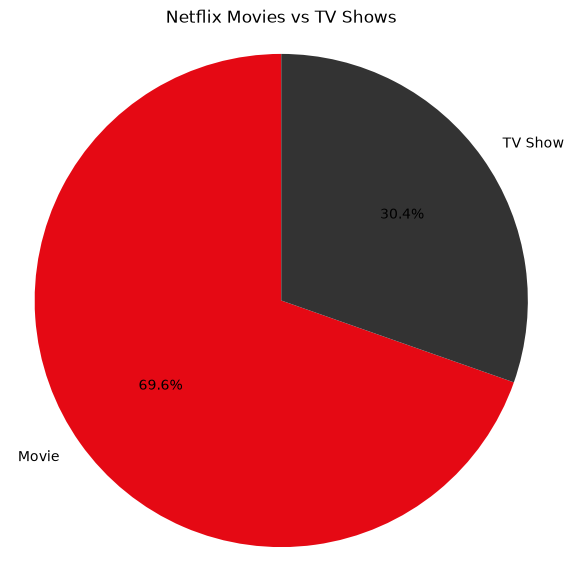

In [19]:
plt.figure(figsize=(7, 7))

plt.pie(
    content_count.values,
    labels=content_count.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E50914", "#333333"]
)

plt.title("Netflix Movies vs TV Shows")
plt.axis("equal")
plt.show()

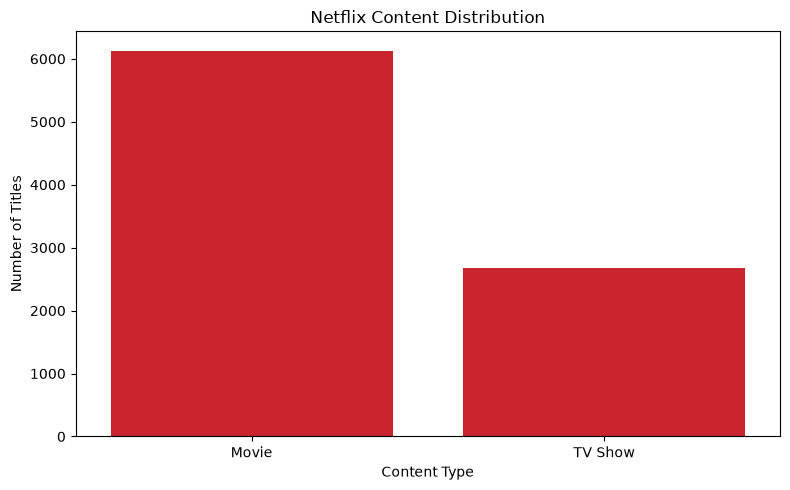

In [20]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="type",
    order=["Movie", "TV Show"],
    color="#E50914"
)

plt.title("Netflix Content Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()

plt.savefig(
    "../visuals/content_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Business Insight 1: Content Type Distribution

Objective: Understand the distribution of movies and TV shows in the Netflix dataset.

Findings:
- Total movies: 6131
- Total TV shows: 2676
- Movie percentage: 69.6%
- TV show percentage: 30.4%

Interpretation: The dataset contains a higher proportion of [Movies/TV Shows], indicating that this content type represents the larger share of the catalog captured in the dataset.

Business implication: The content mix could inform further investigation into Netflix's catalog strategy. However, catalog counts alone cannot establish audience preferences or viewing demand.

In [21]:
print(df["release_year"].describe())
print("Missing release years:", df["release_year"].isnull().sum())
print("Earliest release year:", df["release_year"].min())
print("Latest release year:", df["release_year"].max())

count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64
Missing release years: 0
Earliest release year: 1925
Latest release year: 2021


In [22]:
release_year_counts = df["release_year"].value_counts().sort_index()

print(release_year_counts.tail(20))

release_year
2002      51
2003      61
2004      64
2005      80
2006      96
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64


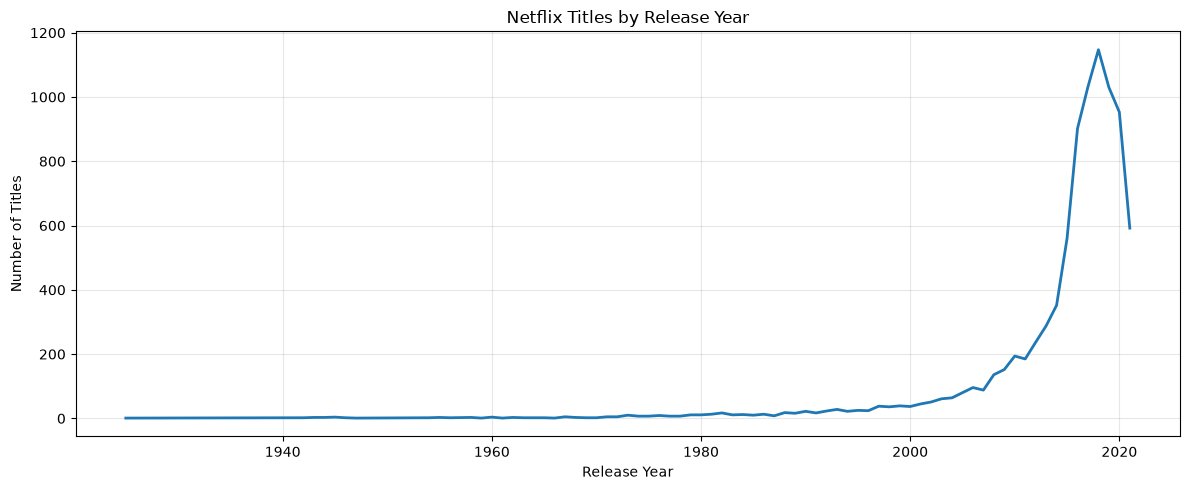

In [23]:
yearly_releases = (
    df.dropna(subset=["release_year"])
      .groupby("release_year")
      .size()
      .sort_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_releases.index,
    yearly_releases.values,
    linewidth=2
)

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../visuals/titles_by_release_year.png", dpi=300)
plt.show()

In [25]:
df["year_added"] = df["date_added"].dt.year

print(df[["title", "date_added", "year_added"]].head(10))

                              title date_added  year_added
0              Dick Johnson Is Dead 2021-09-25      2021.0
1                     Blood & Water 2021-09-24      2021.0
2                         Ganglands 2021-09-24      2021.0
3             Jailbirds New Orleans 2021-09-24      2021.0
4                      Kota Factory 2021-09-24      2021.0
5                     Midnight Mass 2021-09-24      2021.0
6  My Little Pony: A New Generation 2021-09-24      2021.0
7                           Sankofa 2021-09-24      2021.0
8     The Great British Baking Show 2021-09-24      2021.0
9                      The Starling 2021-09-24      2021.0


In [26]:
added_year_counts = (
    df.dropna(subset=["year_added"])
      .groupby("year_added")
      .size()
      .sort_index()
)

print(added_year_counts)

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
dtype: int64


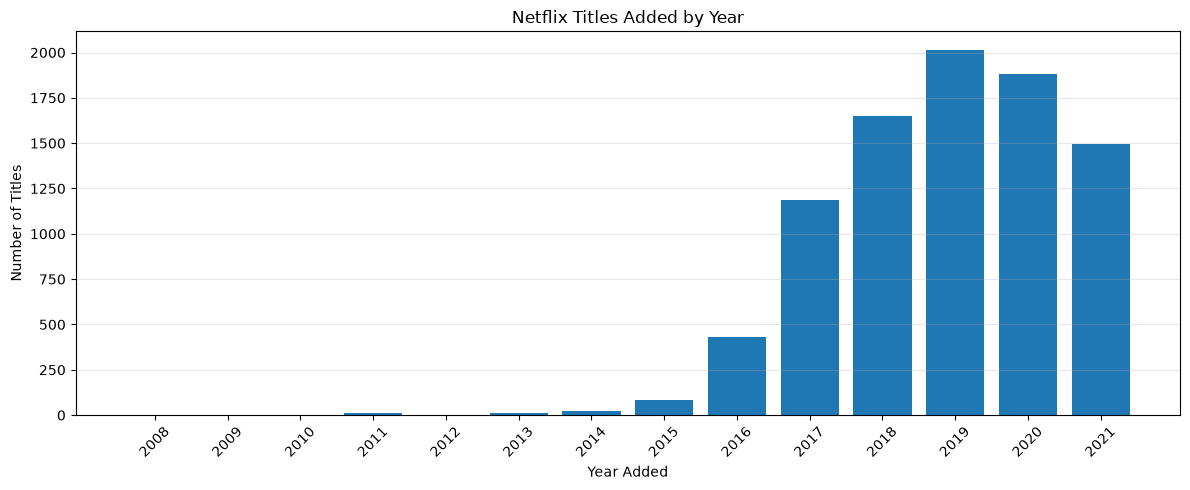

In [27]:
plt.figure(figsize=(12, 5))

plt.bar(
    added_year_counts.index,
    added_year_counts.values
)

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(added_year_counts.index, rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../visuals/titles_added_by_year.png", dpi=300)
plt.show()

In [28]:
content_over_time = (
    df.dropna(subset=["year_added"])
      .groupby(["year_added", "type"])
      .size()
      .unstack(fill_value=0)
)

print(content_over_time.head())

type        Movie  TV Show
year_added                
2008.0          1        1
2009.0          2        0
2010.0          1        0
2011.0         13        0
2012.0          3        0


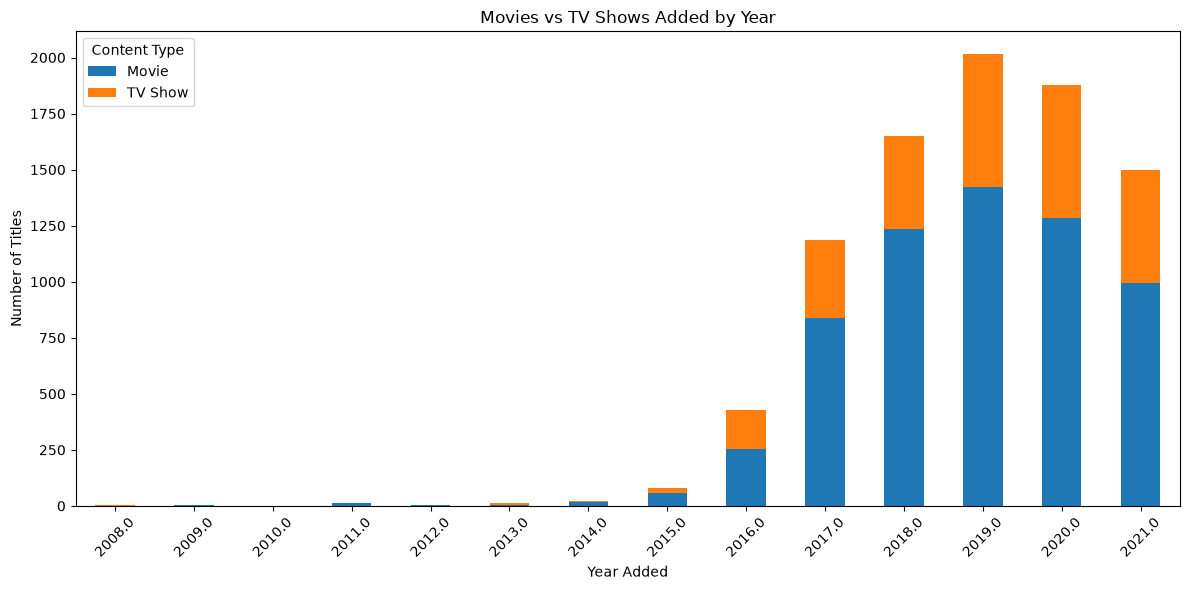

In [29]:
content_over_time.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Movies vs TV Shows Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()

plt.savefig("../visuals/content_type_by_year.png", dpi=300)
plt.show()

In [30]:
yearly_summary = (
    df.dropna(subset=["year_added"])
      .groupby(["year_added", "type"])
      .size()
      .unstack(fill_value=0)
)

yearly_summary["Total Titles"] = yearly_summary.sum(axis=1)

yearly_summary.tail(10)

type,Movie,TV Show,Total Titles
year_added,,,
2012.0,3,0,3
2013.0,6,5,11
2014.0,19,5,24
2015.0,56,26,82
2016.0,253,176,429
2017.0,839,349,1188
2018.0,1237,412,1649
2019.0,1424,592,2016
2020.0,1284,595,1879
